# Event Catering Preparation Under Demand Uncertainty
### Monte Carlo + next-event discrete-event simulation of how much food to prepare

**Summary.** Caterers prepare food from advance bookings, but real attendance and per-guest consumption are random. Too little food causes shortages; too much wastes money. This notebook models attendance (Binomial), per-guest consumption (discrete distribution) and the buffet itself (next-event queueing simulation with inventory depletion), then runs **10,000 Monte Carlo replications per scenario** to find the preparation quantity $Q$ that minimises expected cost subject to a **shortage probability of at most 5%**. The simulator is verified against analytic results (Binomial moments, M/M/1 and Erlang-C queue waits, a hand-solved optimisation case, the newsvendor quantile), and a sensitivity study, a $N^{-1/2}$ convergence study and a multi-category (rice / meat / vegetables) extension are included.

> **All cost, consumption, arrival and service parameters are ASSUMED** (no measured catering records were used). Sensitivity analysis in §5 shows how much each assumption matters. Random seed: `SEED = 42` throughout.

In [1]:
# Setup (Colab: packages are preinstalled; this keeps the notebook reproducible elsewhere)
!pip install -q numpy scipy matplotlib pandas

import os, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from math import factorial

SEED = 42                                   # master seed (reproducibility)
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "font.size": 10})
T0 = time.time()

## 1. Problem and question

Event caterers in Sri Lanka typically cook against advance guest bookings. On the day, the number who attend and how many portions each guest takes are uncertain. Shortages hurt customer satisfaction; surplus wastes ingredients (the food-service sector is a major source of food waste [5]).

**Question.** For an event with $N$ invited guests (100 to 500), *how many portions $Q$ should be prepared to minimise expected total cost while keeping the probability of any food shortage at or below 5%?* And how sensitive is that answer to attendance rate, consumption variability and the cost structure?

## 2. Model, assumptions and equations

**Assumptions** (all parameters assumed; see §5 sensitivity)
1. Each invited guest attends independently with probability $p$.
2. Each attending guest takes $X$ portions, i.i.d., from a discrete distribution on $\{0,1,2,3\}$ (mean 1.5).
3. Guests arrive as a Poisson stream (rate $\lambda$) truncated after the $A$ attendees; $c$ servers at the buffet, exponential service (rate $\mu$ each), FIFO queue.
4. Food is taken when a guest's service completes; if stock runs short the guest receives what remains (partial service) and the rest is *unmet demand*.
5. Preparation is fixed before the event (single period, no re-cooking). Costs: $c_\text{prep}$ per prepared portion, $c_\text{short}$ per unmet portion (LKR).

**Input modelling and random variate generation**

$$A\sim\text{Binomial}(N,p),\qquad E[A]=Np,\qquad D=\sum_{i=1}^{A}X_i .$$

Given $A$, the numbers of guests taking each portion size are $\text{Multinomial}(A,\boldsymbol\pi)$, so $D=\sum_k v_k n_k$ is generated in one vectorised draw. By the law of total variance
$$E[D]=Np\,\mu_X,\qquad \operatorname{Var}(D)=Np\,\sigma_X^2+Np(1-p)\,\mu_X^2 .$$
Inter-arrival times use inverse-transform sampling: $T=-\ln(U)/\lambda$, $U\sim U[0,1]$.

**Cost and decision problem**
$$C(Q)=c_\text{prep}\,Q+c_\text{short}\,(D-Q)^+,\qquad Q^\*=\arg\min_Q E[C(Q)]\ \ \text{s.t.}\ \ P(D>Q)\le\alpha=0.05 .$$
Unconstrained, a one-unit increase in $Q$ changes expected cost by $c_\text{prep}-c_\text{short}P(D>Q)$, so the optimum is the smallest $Q$ with
$$F_D(Q)\ \ge\ 1-\frac{c_\text{prep}}{c_\text{short}}\quad(\text{newsvendor critical fractile}).$$

**Monte Carlo estimation (law of large numbers)**
$$\hat C=\frac1n\sum_{j=1}^{n}C_j,\qquad \text{95\% CI}=\hat C\pm1.96\,\frac{s}{\sqrt n},\qquad \text{error}\propto n^{-1/2}.$$
All candidate $Q$ are evaluated on the *same* $n$ demand draws (common random numbers), which removes noise from comparisons between quantities.

**Discrete-event simulation (next-event time advance).** State: clock, busy servers, FIFO queue, inventory. Future-event list (binary heap) holds ARRIVAL and DEPARTURE events; the clock jumps to the earliest event. Ties are broken deterministically (departures before arrivals, then insertion order). For queue verification with $\rho=\lambda/(c\mu)<1$:
$$W_q^{M/M/1}=\frac{\lambda}{\mu(\mu-\lambda)},\qquad W_q^{M/M/c}=\frac{C(c,a)}{c\mu-\lambda},\quad C(c,a)=\frac{\frac{a^c}{c!}\frac1{1-\rho}}{\sum_{k=0}^{c-1}\frac{a^k}{k!}+\frac{a^c}{c!}\frac1{1-\rho}},\ a=\frac\lambda\mu .$$

| Component | Concept applied |
|---|---|
| $A$, $X$, inter-arrival and service draws | Input modelling and random variate generation |
| $\hat C$, CIs, shortage probability, $n^{-1/2}$ study | Monte Carlo integration and the law of large numbers |
| Buffet queue, event list, inventory depletion, M/M/c checks | Discrete-event simulation and queueing |

## 3. Implementation

The model is split into: parameters and input models, a fast vectorised Monte Carlo layer (used for the grid search), the next-event DES layer, and a multi-category extension.

In [2]:
# 3.0  Imports and conventions
from dataclasses import dataclass, field, replace
import heapq
import numpy as np

print('Model code loaded')

Model code loaded


In [3]:
# 3.  Parameters
@dataclass(frozen=True)
class Params:
    N: int = 200                      # invited guests
    p: float = 0.90                   # P(an invited guest attends)
    values: tuple = (0, 1, 2, 3)      # portions a guest may take
    probs: tuple = (0.05, 0.50, 0.35, 0.10)   # their probabilities (mean 1.5)
    c_prep: float = 300.0             # LKR per prepared portion
    c_short: float = 1500.0           # LKR penalty per unmet portion
    lam: float = 5.0                  # guest arrival rate (guests/min)
    mu: float = 1.5                   # service rate per server (guests/min)
    servers: int = 4                  # buffet service points

    @property
    def mean_portions(self):
        return float(np.dot(self.values, self.probs))

    @property
    def var_portions(self):
        v = np.array(self.values, float)
        return float(np.dot(v**2, self.probs) - self.mean_portions**2)

    @property
    def mean_demand(self):            # E[D] = N p E[X]  (Wald)
        return self.N * self.p * self.mean_portions

    @property
    def var_demand(self):             # Var D = Np E[X^2] ... via law of total variance
        EX, VX = self.mean_portions, self.var_portions
        return self.N * self.p * VX + self.N * self.p * (1 - self.p) * EX**2


In [4]:
# 3.  Input models (random variate generation)
def draw_attendance(par, rng, size):
    """A ~ Binomial(N, p)."""
    return rng.binomial(par.N, par.p, size=size)


def draw_demand(par, rng, size):
    """Total portions D = sum of X_i over the A attending guests.
    Given A, the counts of guests choosing each portion size are
    Multinomial(A, probs); D = counts . values.  Fully vectorised."""
    A = draw_attendance(par, rng, size)
    counts = rng.multinomial(A, par.probs)          # shape (size, len(values))
    return A, counts @ np.array(par.values)


In [5]:
# 3.  Fast layer: Monte Carlo + grid search with common random numbers
def ci95(x, axis=0):
    """Mean and 95% half-width (normal approx, 1.96 s/sqrt(n))."""
    n = x.shape[axis]
    m = x.mean(axis=axis)
    hw = 1.96 * x.std(axis=axis, ddof=1) / np.sqrt(n)
    return m, hw


def evaluate_grid(par, Qgrid, reps=10_000, seed=42):
    """Evaluate every Q in Qgrid on the SAME `reps` demand draws."""
    rng = np.random.default_rng(seed)
    _, D = draw_demand(par, rng, reps)
    Q = np.asarray(Qgrid)[None, :]
    D = D[:, None]
    unmet = np.maximum(D - Q, 0)
    left = np.maximum(Q - D, 0)
    short = (unmet > 0).astype(float)
    cost = par.c_prep * Q + par.c_short * unmet
    out = {"Q": np.asarray(Qgrid)}
    for name, arr in [("cost", cost), ("unused", left), ("unmet", unmet), ("p_short", short)]:
        m, hw = ci95(arr)
        out[name], out[name + "_hw"] = m, hw
    return out


def optimise(par, Qgrid, reps=10_000, seed=42, alpha=0.05):
    """Min expected cost s.t. P(shortage) <= alpha.  Returns dict."""
    g = evaluate_grid(par, Qgrid, reps, seed)
    feas = g["p_short"] <= alpha
    if not feas.any():
        raise ValueError("No Q in grid satisfies the shortage constraint; widen the grid.")
    idx_f = np.where(feas)[0]
    i = idx_f[np.argmin(g["cost"][idx_f])]
    j = int(np.argmin(g["cost"]))                    # unconstrained optimum
    return {"grid": g, "i_opt": i, "Q_opt": int(g["Q"][i]), "i_unc": j,
            "Q_unc": int(g["Q"][j]), "constraint_binding": bool(i != j)}


In [6]:
# 3.  DES layer: next-event simulation with a future-event list (heapq)
ARRIVAL, DEPARTURE = 1, 0     # on equal times, departures are processed first


def simulate_event(par, Q, rng, n_guests=None, portions=None):
    """One catering event, next-event time advance.

    State: clock, servers busy, FIFO queue (arrival time, portions wanted),
           inventory.  Event list: (time, type, seq, payload) in a binary heap.
    A guest takes its portions when service COMPLETES; if inventory is short it
    receives what is left (partial service) and the rest is unmet demand.
    n_guests / portions may be injected (used by deterministic verification).
    """
    A = draw_attendance(par, rng, None) if n_guests is None else n_guests
    A = int(A)
    want = (rng.choice(par.values, size=A, p=par.probs)
            if portions is None else np.asarray(portions))
    gaps = rng.exponential(1.0 / par.lam, size=A)
    arr_t = np.cumsum(gaps)

    seq = 0
    fel = []                                    # future event list
    for k in range(A):
        heapq.heappush(fel, (arr_t[k], ARRIVAL, seq, k)); seq += 1

    inv, busy, queue = int(Q), 0, []            # queue: list used as FIFO (head index)
    qhead = 0
    served = unmet = guests_short = 0
    waits = np.zeros(A)
    stockout_time = np.nan
    clock = 0.0

    def start_service(k, now):
        nonlocal busy, seq
        busy += 1
        waits[k] = now - arr_t[k]
        s = rng.exponential(1.0 / par.mu)
        heapq.heappush(fel, (now + s, DEPARTURE, seq, k)); seq += 1

    while fel:
        clock, etype, _, k = heapq.heappop(fel)
        if etype == ARRIVAL:
            if busy < par.servers:
                start_service(k, clock)
            else:
                queue.append(k)
        else:                                    # DEPARTURE: guest k finishes service
            busy -= 1
            take = min(int(want[k]), inv)
            inv -= take
            served += take
            miss = int(want[k]) - take
            unmet += miss
            if miss > 0:
                guests_short += 1
                if np.isnan(stockout_time):
                    stockout_time = clock
            if qhead < len(queue):
                start_service(queue[qhead], clock); qhead += 1

    requested = int(want.sum())
    # --- run-time conservation checks (cheap, always on) ---
    assert Q == served + inv, "prepared != served + leftover"
    assert requested == served + unmet, "requested != served + unmet"
    return {"A": A, "requested": requested, "served": served, "leftover": inv,
            "unmet": unmet, "guests_short": guests_short,
            "mean_wait": waits.mean() if A else 0.0, "max_wait": waits.max() if A else 0.0,
            "stockout_time": stockout_time, "end_time": clock}


def run_des(par, Q, reps=2_000, seed=42):
    """Independent replications of the DES; returns arrays + (mean, hw) summary."""
    rng = np.random.default_rng(seed)
    rows = [simulate_event(par, Q, rng) for _ in range(reps)]
    keys = rows[0].keys()
    arr = {k: np.array([r[k] for r in rows], float) for k in keys}
    arr["cost"] = par.c_prep * Q + par.c_short * arr["unmet"]
    arr["shortage"] = (arr["unmet"] > 0).astype(float)
    return arr


In [7]:
# 3.  M/M/c verification helper (infinite-style long run, warm-up discarded)
def mm_queue_wait(lam, mu, servers, n_cust, rng, warmup=2000):
    """Mean wait in queue of a FIFO M/M/c via the same next-event logic."""
    arr_t = np.cumsum(rng.exponential(1.0 / lam, size=n_cust))
    fel, seq = [], 0
    for k in range(n_cust):
        heapq.heappush(fel, (arr_t[k], ARRIVAL, seq, k)); seq += 1
    busy, queue, qhead = 0, [], 0
    waits = np.zeros(n_cust)
    while fel:
        t, et, _, k = heapq.heappop(fel)
        if et == ARRIVAL:
            if busy < servers:
                busy += 1; waits[k] = 0.0
                heapq.heappush(fel, (t + rng.exponential(1 / mu), DEPARTURE, seq, k)); seq += 1
            else:
                queue.append(k)
        else:
            busy -= 1
            if qhead < len(queue):
                j = queue[qhead]; qhead += 1; busy += 1
                waits[j] = t - arr_t[j]
                heapq.heappush(fel, (t + rng.exponential(1 / mu), DEPARTURE, seq, j)); seq += 1
    return waits[warmup:].mean()


In [8]:
# 3.  Stretch: multi-category menu (rice / meat / vegetables)
def draw_multi_demand(N, p, cats, rng, size):
    """Shared attendance A across categories; per-category portion distributions.
    cats: {name: (values, probs)}.  Returns {name: D_array}, A_array."""
    A = rng.binomial(N, p, size=size)
    D = {name: rng.multinomial(A, pr) @ np.array(v) for name, (v, pr) in cats.items()}
    return D, A


def optimise_demand(D, c_prep, c_short, Qgrid, alpha=0.05):
    """Grid search on a pre-drawn demand sample D (1-D array)."""
    Q = np.asarray(Qgrid)[None, :]
    unmet = np.maximum(D[:, None] - Q, 0)
    cost = (c_prep * Q + c_short * unmet).mean(axis=0)
    ps = (unmet > 0).mean(axis=0)
    feas = np.where(ps <= alpha)[0]
    i = feas[np.argmin(cost[feas])]
    return int(Qgrid[i]), float(cost[i]), float(ps[i])


## 4. Verification

Each check below is an `assert`, so a failure stops the notebook. Statistical checks use a tolerance of 3 standard errors.

| # | Check | Type |
|---|---|---|
| V1 | $E[A]=Np$, $E[D]$, $\operatorname{Var}(D)$ vs theory | analytic |
| V2 | No randomness $\Rightarrow$ demand exactly $2N$ | limiting case |
| V3 | prepared = served + leftover; requested = served + unmet (10,000 runs) | conservation |
| V4 | DES aggregates = fast-layer aggregates | independent implementations |
| V5 | M/M/1 and M/M/4 simulated $W_q$ vs closed form | analytic |
| V6 | Optimiser vs a hand-solved case | hand calculation |
| V7 | Grid-search optimum = newsvendor quantile | analytic, independent method |

In [9]:
par = Params()
se = lambda x: x.std(ddof=1) / np.sqrt(len(x))

# --- V1: Binomial attendance and demand moments -------------------------------------------
A, D = draw_demand(par, np.random.default_rng(SEED), 200_000)
print(f"V1  E[A]: sim {A.mean():.3f} vs theory {par.N*par.p:.3f}   | E[D]: sim {D.mean():.3f} vs {par.mean_demand:.3f}"
      f"   | Var D: sim {D.var():.1f} vs {par.var_demand:.1f}")
assert abs(A.mean() - par.N*par.p) < 3*se(A)
assert abs(D.mean() - par.mean_demand) < 3*se(D)
assert abs(D.var() / par.var_demand - 1) < 0.02

# --- V2: deterministic limit ----------------------------------------------------------------
pd_ = Params(N=50, p=1.0, values=(2,), probs=(1.0,))
r1 = simulate_event(pd_, 100, np.random.default_rng(SEED))
r2 = simulate_event(pd_, 90,  np.random.default_rng(SEED))
print(f"V2  deterministic: requested={r1['requested']} (expect 100), unmet={r1['unmet']}; with Q=90 unmet={r2['unmet']} (expect 10)")
assert r1["requested"] == 100 and r1["unmet"] == 0 and r1["leftover"] == 0 and r2["unmet"] == 10

# --- V3: conservation (asserted inside simulate_event on every run) -------------------------
des = run_des(par, 285, reps=10_000, seed=SEED)
assert np.all(285 == des["served"] + des["leftover"]) and np.all(des["requested"] == des["served"] + des["unmet"])
print("V3  conservation holds in all 10,000 DES runs")

# --- V4: DES vs fast layer (same model, different code paths) -------------------------------
g = evaluate_grid(par, [285], reps=200_000, seed=SEED + 1)
for k_des, k_fast in [("unmet", "unmet"), ("leftover", "unused"), ("cost", "cost")]:
    diff = abs(des[k_des].mean() - g[k_fast][0]); tol = 3 * np.hypot(se(des[k_des]), g[k_fast + "_hw"][0] / 1.96)
    print(f"V4  {k_des:9s}: DES {des[k_des].mean():9.2f}  fast {g[k_fast][0]:9.2f}  |diff|={diff:.2f} <= {tol:.2f}")
    assert diff <= tol
pdiff = abs(des["shortage"].mean() - g["p_short"][0]); ptol = 3 * np.hypot(se(des["shortage"]), g["p_short_hw"][0] / 1.96)
print(f"V4  P(short) : DES {des['shortage'].mean():.4f}  fast {g['p_short'][0]:.4f}"); assert pdiff <= ptol

# --- V5: queue waits vs closed forms --------------------------------------------------------
def erlang_c_wq(lam, mu, c):
    a, rho = lam / mu, lam / (c * mu)
    top = a**c / factorial(c) / (1 - rho)
    return (top / (sum(a**k / factorial(k) for k in range(c)) + top)) / (c * mu - lam)

for lam, mu, c, n in [(6, 8, 1, 40_000), (par.lam, par.mu, par.servers, 40_000)]:
    w = np.array([mm_queue_wait(lam, mu, c, n, np.random.default_rng(SEED + s)) for s in range(20)])
    th = erlang_c_wq(lam, mu, c)
    print(f"V5  M/M/{c} (lam={lam}, mu={mu}, rho={lam/(c*mu):.2f}): Wq sim {w.mean():.4f} +/- {1.96*se(w):.4f}  theory {th:.4f}")
    assert abs(w.mean() - th) < 3 * se(w)
assert abs(erlang_c_wq(6, 8, 1) - 6 / (8 * (8 - 6))) < 1e-12        # Erlang-C reduces to M/M/1

# --- V6: hand-solved optimisation case ------------------------------------------------------
# N=4, p=.5, 1 portion each => D ~ Bin(4,.5), pmf (1,4,6,4,1)/16. c_prep=1, c_short=4.
# By hand: E[C(2)]=3.5, E[C(3)]=3.25, E[C(4)]=4.  Unconstrained Q=3. P(D>3)=1/16=.0625>.05 => constrained Q=4.
pt = Params(N=4, p=0.5, values=(1,), probs=(1.0,), c_prep=1.0, c_short=4.0)
o = optimise(pt, np.arange(0, 7), reps=400_000, seed=SEED)
g_ = o["grid"]
print(f"V6  grid search: Q_unc={o['Q_unc']} (hand 3), cost {g_['cost'][3]:.3f} (hand 3.250);  Q_opt={o['Q_opt']} (hand 4), cost {g_['cost'][4]:.3f} (hand 4.000)")
assert o["Q_unc"] == 3 and o["Q_opt"] == 4
assert abs(g_["cost"][3] - 3.25) < 3 * g_["cost_hw"][3] / 1.96 and abs(g_["cost"][2] - 3.5) < 3 * g_["cost_hw"][2] / 1.96

# --- V7: grid-search optimum vs newsvendor critical-fractile quantile ------------------------
o7 = optimise(par, np.arange(230, 340), reps=10_000, seed=SEED)
_, Dbig = draw_demand(par, np.random.default_rng(SEED + 2), 1_000_000)
q_nv = np.quantile(Dbig, 1 - par.c_prep / par.c_short, method="higher")
print(f"V7  unconstrained grid optimum {o7['Q_unc']}  vs newsvendor quantile (fractile {1-par.c_prep/par.c_short:.2f}) {q_nv:.0f}")
assert abs(o7["Q_unc"] - q_nv) <= 1
print("\nALL VERIFICATION CHECKS PASSED")

V1  E[A]: sim 180.000 vs theory 180.000   | E[D]: sim 270.022 vs 270.000   | Var D: sim 139.6 vs 139.5
V2  deterministic: requested=100 (expect 100), unmet=0; with Q=90 unmet=10 (expect 10)
V3  conservation holds in all 10,000 DES runs
V4  unmet    : DES      0.55  fast      0.57  |diff|=0.02 <= 0.07
V4  leftover : DES     15.58  fast     15.59  |diff|=0.00 <= 0.33
V4  cost     : DES  86329.65  fast  86357.41  |diff|=27.76 <= 103.49
V4  P(short) : DES 0.0928  fast 0.0946
V5  M/M/1 (lam=6, mu=8, rho=0.75): Wq sim 0.3735 +/- 0.0071  theory 0.3750
V5  M/M/4 (lam=5.0, mu=1.5, rho=0.83): Wq sim 0.6596 +/- 0.0192  theory 0.6577
V6  grid search: Q_unc=3 (hand 3), cost 3.249 (hand 3.250);  Q_opt=4 (hand 4), cost 4.000 (hand 4.000)
V7  unconstrained grid optimum 280  vs newsvendor quantile (fractile 0.80) 280

ALL VERIFICATION CHECKS PASSED


## 5. Experiments and results

Baseline scenario: $N=200$, $p=0.9$, portions $\{0,1,2,3\}$ with probabilities $(0.05,0.50,0.35,0.10)$, $c_\text{prep}=300$ LKR, $c_\text{short}=1500$ LKR, $\lambda=5$/min, $\mu=1.5$/min per server, 4 servers. All results use 10,000 replications and 95% CIs unless stated.

### 5.1 Baseline: grid search over $Q$

Unconstrained optimum Q = 280   |   With P(shortage) <= 5%:  Q* = 289   (E[D] = 270)
At Q*: cost 87,103 +/- 45 LKR | unused 19.3 +/- 0.2 portions | P(short) 0.050 +/- 0.004


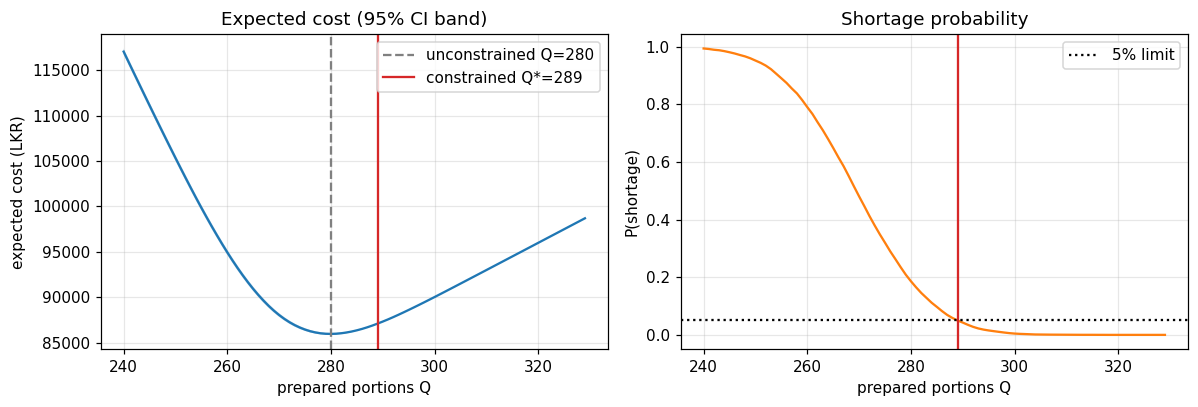

In [10]:
Qg = np.arange(240, 330)
base = optimise(par, Qg, reps=10_000, seed=SEED)
g, i = base["grid"], base["i_opt"]
print(f"Unconstrained optimum Q = {base['Q_unc']}   |   With P(shortage) <= 5%:  Q* = {base['Q_opt']}   (E[D] = {par.mean_demand:.0f})")
print(f"At Q*: cost {g['cost'][i]:,.0f} +/- {g['cost_hw'][i]:,.0f} LKR | unused {g['unused'][i]:.1f} +/- {g['unused_hw'][i]:.1f} portions | "
      f"P(short) {g['p_short'][i]:.3f} +/- {g['p_short_hw'][i]:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(g["Q"], g["cost"], color="C0"); ax[0].fill_between(g["Q"], g["cost"]-g["cost_hw"], g["cost"]+g["cost_hw"], alpha=.3)
ax[0].axvline(base["Q_unc"], ls="--", c="gray", label=f"unconstrained Q={base['Q_unc']}"); ax[0].axvline(base["Q_opt"], c="C3", label=f"constrained Q*={base['Q_opt']}")
ax[0].set(xlabel="prepared portions Q", ylabel="expected cost (LKR)", title="Expected cost (95% CI band)"); ax[0].legend()
ax[1].plot(g["Q"], g["p_short"], color="C1"); ax[1].axhline(.05, c="k", ls=":", label="5% limit")
ax[1].axvline(base["Q_opt"], c="C3"); ax[1].set(xlabel="prepared portions Q", ylabel="P(shortage)", title="Shortage probability"); ax[1].legend()
plt.tight_layout(); plt.savefig("figures/baseline_grid_search.png"); plt.show()

### 5.2 Full discrete-event simulation at $Q^*$ (10,000 events)

The DES adds what the fast layer cannot: queueing delay and *when* the food runs out.

In [11]:
Qs = base["Q_opt"]
d = run_des(par, Qs, reps=10_000, seed=SEED)
def row(name, x, unit=""):
    return {"metric": name, "mean": x.mean(), "95% CI half-width": 1.96 * x.std(ddof=1) / np.sqrt(len(x)), "unit": unit}
tbl = pd.DataFrame([row("unused (leftover) portions", d["leftover"], "portions"), row("unmet portions", d["unmet"], "portions"),
                    row("P(any shortage)", d["shortage"], "probability"), row("total cost", d["cost"], "LKR"),
                    row("guests short-served", d["guests_short"], "guests"), row("mean wait in queue", d["mean_wait"], "min"),
                    row("longest wait in event", d["max_wait"], "min")])
print(f"DES at Q* = {Qs}, N=200, p=0.9, 10,000 replications, seed {SEED}"); display(tbl.round(3))
so = d["stockout_time"][~np.isnan(d["stockout_time"])]
print(f"Events with a stock-out: {len(so)}; median stock-out time {np.median(so):.1f} min after the first arrival (event lasts ~{d['end_time'].mean():.0f} min)")

DES at Q* = 289, N=200, p=0.9, 10,000 replications, seed 42


,metric,mean,95% CI half-width,unit
0,unused (leftover) portions,19.288,0.221,portions
1,unmet portions,0.257,0.029,portions
2,P(any shortage),0.048,0.004,probability
3,total cost,87085.800,43.023,LKR
4,guests short-served,0.170,0.019,guests
5,mean wait in queue,0.491,0.008,min
6,longest wait in event,2.036,0.018,min


Events with a stock-out: 475; median stock-out time 37.6 min after the first arrival (event lasts ~38 min)


### 5.3 Event size: $N=100\ldots500$

,N,E[D],Q*,buffer Q*-E[D],buffer %,cost (LKR),cost CI,unused,P(short)
0,100,135.0,149,14.0,10.37,44934.60,28.43,14.08,0.04
1,200,270.0,289,19.0,7.04,87103.35,45.03,19.25,0.05
2,300,405.0,429,24.0,5.93,129153.30,53.19,24.13,0.05
3,400,540.0,568,28.0,5.19,170916.00,59.65,28.11,0.05
4,500,675.0,706,31.0,4.59,212388.45,68.68,31.24,0.05


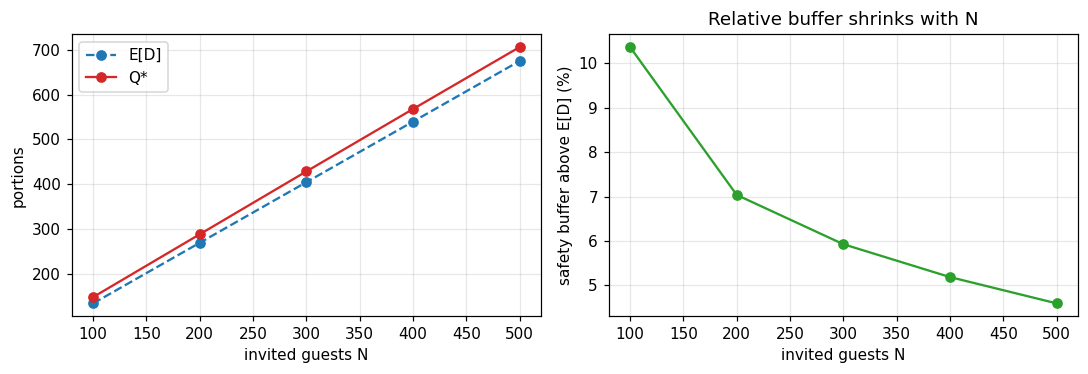

In [12]:
rows = []
for N in [100, 200, 300, 400, 500]:
    pr = replace(par, N=N)
    sd = np.sqrt(pr.var_demand); Qgrid = np.arange(int(pr.mean_demand - 4*sd), int(pr.mean_demand + 6*sd) + 2)
    o = optimise(pr, Qgrid, reps=10_000, seed=SEED); g, i = o["grid"], o["i_opt"]
    rows.append({"N": N, "E[D]": pr.mean_demand, "Q*": o["Q_opt"], "buffer Q*-E[D]": o["Q_opt"] - pr.mean_demand,
                 "buffer %": 100 * (o["Q_opt"] / pr.mean_demand - 1), "cost (LKR)": g["cost"][i], "cost CI": g["cost_hw"][i],
                 "unused": g["unused"][i], "P(short)": g["p_short"][i]})
scale = pd.DataFrame(rows); display(scale.round(2))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(scale.N, scale["E[D]"], "o--", label="E[D]"); ax[0].plot(scale.N, scale["Q*"], "o-", c="C3", label="Q*"); ax[0].set(xlabel="invited guests N", ylabel="portions"); ax[0].legend()
ax[1].plot(scale.N, scale["buffer %"], "o-", c="C2"); ax[1].set(xlabel="invited guests N", ylabel="safety buffer above E[D] (%)", title="Relative buffer shrinks with N")
plt.tight_layout(); plt.savefig("figures/scaling_with_N.png"); plt.show()

### 5.4 Sensitivity analysis (one-at-a-time, 20 independent seeds)

For each setting, the optimisation is repeated with 20 different seeds (10,000 replications each). We report the mean $Q^*$ (5% rule) with its min-max range across seeds, the *cost-only* optimum $Q$ (no shortage limit), and the mean cost with a 95% CI.

,parameter,value,E[D],Q* mean,Q* min,Q* max,Q unconstrained,cost mean,cost 95% CI
0,attendance p,0.7,210.0,231.7,231,232,221.0,69918.1,53.4
1,attendance p,0.8,240.0,260.8,260,261,250.8,78639.9,49.9
2,attendance p,0.9,270.0,289.4,289,290,280.0,87205.5,58.2
3,attendance p,0.95,285.0,303.6,303,304,294.4,91415.2,58.4
4,attendance p,1.0,300.0,317.2,317,318,309.0,95499.7,46.9
5,consumption variance,low (0.25),270.0,285.0,285,285,278.0,85791.8,6.7
6,consumption variance,base (0.55),270.0,289.4,289,290,280.0,87205.5,58.2
7,consumption variance,high (1.25),270.0,296.8,296,297,283.9,89571.7,47.0
8,shortage penalty (LKR),600,270.0,289.4,289,290,270.0,86983.2,63.3
9,shortage penalty (LKR),1000,270.0,289.4,289,290,276.0,87082.0,60.9


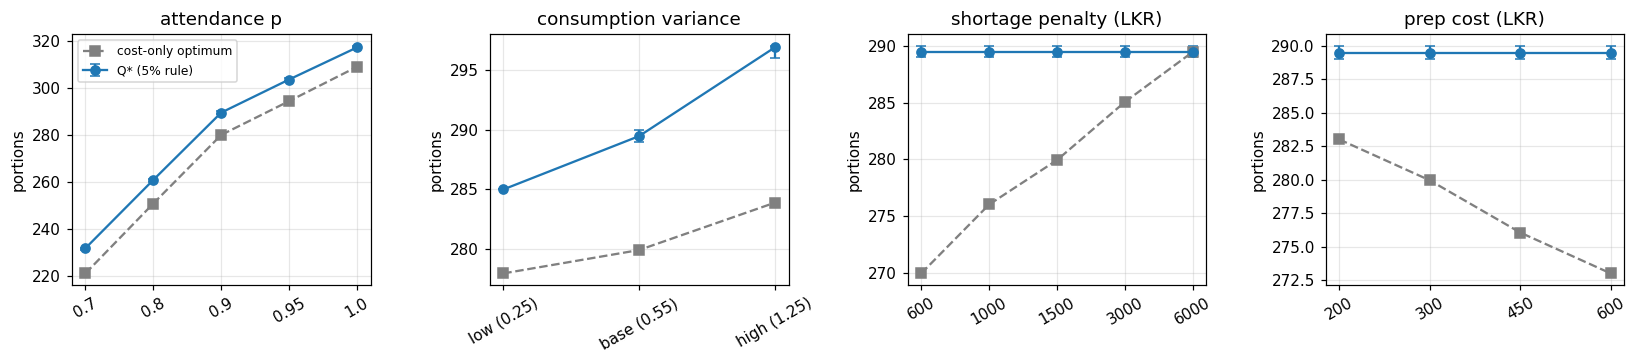

In [13]:
def qgrid(pr, lo=4, hi=6):
    sd = np.sqrt(pr.var_demand); return np.arange(int(pr.mean_demand - lo*sd), int(pr.mean_demand + hi*sd) + 2)

def q_over_seeds(pr, n_seeds=20, reps=10_000):
    qs, cs, qu = [], [], []
    for s in range(n_seeds):
        o = optimise(pr, qgrid(pr), reps, seed=1000 + s); qs.append(o["Q_opt"]); cs.append(o["grid"]["cost"][o["i_opt"]]); qu.append(o["Q_unc"])
    return np.array(qs), np.array(cs), np.array(qu)

sweeps = {
  "attendance p":            [(f"{v}", replace(par, p=v)) for v in (0.7, 0.8, 0.9, 0.95, 1.0)],
  "consumption variance":    [("low (0.25)",  replace(par, probs=(0.0, 0.5, 0.5, 0.0))), ("base (0.55)", par),
                              ("high (1.25)", replace(par, probs=(0.25, 0.25, 0.25, 0.25)))],
  "shortage penalty (LKR)":  [(f"{v}", replace(par, c_short=v)) for v in (600, 1000, 1500, 3000, 6000)],
  "prep cost (LKR)":         [(f"{v}", replace(par, c_prep=v)) for v in (200, 300, 450, 600)],
}
rows = []
for name, lst in sweeps.items():
    for lab, pr in lst:
        qs, cs, qu = q_over_seeds(pr)
        rows.append({"parameter": name, "value": lab, "E[D]": pr.mean_demand, "Q* mean": qs.mean(), "Q* min": qs.min(), "Q* max": qs.max(), "Q unconstrained": qu.mean(),
                     "cost mean": cs.mean(), "cost 95% CI": 1.96 * cs.std(ddof=1) / np.sqrt(len(cs))})
sens = pd.DataFrame(rows); display(sens.round(1))

fig, axs = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, (name, grp) in zip(axs, sens.groupby("parameter", sort=False)):
    ax.errorbar(range(len(grp)), grp["Q* mean"], yerr=[grp["Q* mean"] - grp["Q* min"], grp["Q* max"] - grp["Q* mean"]], fmt="o-", capsize=3, label="Q* (5% rule)")
    ax.plot(range(len(grp)), grp["Q unconstrained"], "s--", c="gray", label="cost-only optimum")
    ax.set_xticks(range(len(grp))); ax.set_xticklabels(grp["value"], rotation=30); ax.set(title=name, ylabel="portions")
axs[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/sensitivity.png"); plt.show()

### 5.5 Monte Carlo convergence ($n^{-1/2}$)

For the cost at fixed $Q^*$, we draw 200 independent batches at each sample size $n$ and measure the RMS error of the batch mean against a 1,000,000-draw reference. On log-log axes the slope should be $-1/2$.

fitted log-log slope = -0.475  (theory -0.5)


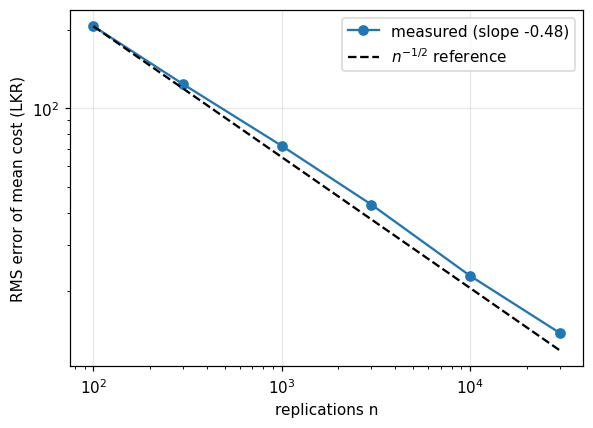

In [14]:
ref_rng = np.random.default_rng(SEED + 5)
_, Dref = draw_demand(par, ref_rng, 1_000_000)
cost_of = lambda D: par.c_prep * Qs + par.c_short * np.maximum(D - Qs, 0)
ref_mean = cost_of(Dref).mean()
ns = np.array([100, 300, 1000, 3000, 10_000, 30_000]); rmse = []
for n in ns:
    rng = np.random.default_rng(SEED + int(n))
    errs = [cost_of(draw_demand(par, rng, n)[1]).mean() - ref_mean for _ in range(200)]
    rmse.append(np.sqrt(np.mean(np.square(errs))))
slope, icpt = np.polyfit(np.log10(ns), np.log10(rmse), 1)
print(f"fitted log-log slope = {slope:.3f}  (theory -0.5)")
assert -0.6 < slope < -0.4
plt.figure(figsize=(5.5, 4)); plt.loglog(ns, rmse, "o-", label=f"measured (slope {slope:.2f})")
plt.loglog(ns, rmse[0] * np.sqrt(ns[0] / ns), "k--", label="$n^{-1/2}$ reference")
plt.xlabel("replications n"); plt.ylabel("RMS error of mean cost (LKR)"); plt.legend(); plt.tight_layout(); plt.savefig("figures/mc_convergence.png"); plt.show()

### 5.6 Stretch: multi-category menu (rice, meat, vegetables)

Each category has its own portion distribution, preparation cost and shortage penalty; attendance $A$ is **shared** across categories, so shortages are positively correlated. We compare a per-category 5% limit with a Bonferroni-tightened limit ($0.05/3$) that targets a menu-level risk near 5%. Optimisation uses one sample; the menu-level risk is evaluated on a fresh independent sample.

In [15]:
cats  = {"rice": ((1, 2, 3), (0.25, 0.55, 0.20)), "meat": ((0, 1, 2), (0.20, 0.60, 0.20)), "vegetables": ((0, 1, 2), (0.30, 0.50, 0.20))}
costs = {"rice": (80, 400), "meat": (350, 1750), "vegetables": (120, 600)}          # (c_prep, c_short) LKR/portion, assumed
Dtrain, _ = draw_multi_demand(200, 0.9, cats, np.random.default_rng(SEED), 10_000)
Dtest,  _ = draw_multi_demand(200, 0.9, cats, np.random.default_rng(SEED + 99), 100_000)

out = []
for label, alpha_c in [("per-category 5%", 0.05), ("Bonferroni 5%/3", 0.05 / 3)]:
    Qm, any_short, total = {}, np.zeros(100_000, bool), 0.0
    for k, (cp, cs_) in costs.items():
        Qk, _, _ = optimise_demand(Dtrain[k], cp, cs_, np.arange(Dtrain[k].min(), Dtrain[k].max() + 1), alpha_c)
        Qm[k] = Qk; any_short |= Dtest[k] > Qk; total += cp * Qk + cs_ * np.maximum(Dtest[k] - Qk, 0).mean()
    out.append({"rule": label, **{f"Q {k}": v for k, v in Qm.items()}, "P(any category short)": any_short.mean(), "expected total cost (LKR)": total})
display(pd.DataFrame(out).round(3))

,rule,Q rice,Q meat,Q vegetables,P(any category short),expected total cost (LKR)
0,per-category 5%,371,196,179,0.117,120297.920
1,Bonferroni 5%/3,377,200,183,0.045,122298.204


### 5.7 Reference values for the browser demo

The interactive web demo is checked against these numbers (the browser uses a different random-number stream, so stochastic outputs must agree within the stated statistical tolerance; the deterministic case must match exactly).

In [16]:
ref = run_des(par, 285, reps=10_000, seed=SEED)
r = lambda x: (x.mean(), 1.96 * x.std(ddof=1) / np.sqrt(len(x)))
print("REFERENCE A (stochastic): N=200, p=0.9, Q=285, 4 servers, lambda=5, mu=1.5, 10,000 events")
for name, key in [("mean unused portions", "leftover"), ("P(shortage)", "shortage"), ("mean total cost (LKR)", "cost"), ("mean wait (min)", "mean_wait")]:
    m, hw = r(ref[key]); print(f"   {name:24s} {m:10.3f}  +/- {hw:.3f}")
print("REFERENCE B (deterministic): N=50, p=1, every guest takes exactly 2 portions, Q=90 -> requested 100, served 90, unmet 10, leftover 0")
print(f"\nTotal notebook runtime: {time.time() - T0:.0f} s")

REFERENCE A (stochastic): N=200, p=0.9, Q=285, 4 servers, lambda=5, mu=1.5, 10,000 events
   mean unused portions         15.584  +/- 0.212
   P(shortage)                   0.093  +/- 0.006
   mean total cost (LKR)     86329.650  +/- 65.887
   mean wait (min)               0.491  +/- 0.008
REFERENCE B (deterministic): N=50, p=1, every guest takes exactly 2 portions, Q=90 -> requested 100, served 90, unmet 10, leftover 0

Total notebook runtime: 203 s


## 6. Discussion and limitations

**Findings (baseline, $N=200$, $p=0.9$).** Expected demand is 270 portions. The cost-minimising quantity ignoring risk is 280, which matches the newsvendor critical-fractile quantile exactly. The 5% shortage limit is *binding* and pushes the recommendation up to $Q^*=289$, a safety buffer of about 7% above expected demand. Section 5.3 shows that the *relative* buffer shrinks as events get larger (variance grows like $N$, mean like $N$, so relative uncertainty falls like $1/\sqrt N$). Section 5.4 shows that $Q^*$ is driven by attendance rate and consumption variability (the shape of the demand distribution), *not* by the cost assumptions: while the 5% limit binds, $Q^*$ is simply the 95th percentile of demand whatever $c_\text{prep}$ and $c_\text{short}$ are. Costs change the total bill and the cost-only optimum, and the limit stops binding only when $c_\text{short}\ge 20\,c_\text{prep}$ (fractile $\ge 0.95$). This is good news for a caterer who cannot measure the 'cost' of an unhappy customer, but the 5% target itself becomes the key policy choice. Section 5.6 shows that guaranteeing a menu-level risk requires tighter per-category limits than a naive per-dish 5% rule.

**Limitations.**
- All parameters are assumed, not measured. Real booking and attendance records would let attendance and consumption be calibrated and validated.
- Guests are i.i.d.; real groups (families, tables) create correlated attendance and consumption, which would widen the demand distribution and raise the required buffer.
- Single preparation decision: no top-up cooking during the event, no cost of leftovers beyond the preparation cost.
- Costs of a shortage (penalty per unmet portion) are a modelling proxy for lost goodwill and are the least certain input; §5.4 quantifies its effect.
- The DES aggregates (unused, shortage) are order-independent by conservation; the DES matters for queue delay and stock-out timing, not for the headline $Q^*$.

## 7. References

1. A. M. Law, *Simulation Modeling and Analysis*, 5th ed. New York, NY, USA: McGraw-Hill Education, 2015.

2. K. J. Arrow, T. Harris, and J. Marschak, “Optimal inventory policy,” *Econometrica*, vol. 19, no. 3, pp. 250–272, Jul. 1951, doi: 10.2307/1906813.

3. N. Metropolis and S. Ulam, “The Monte Carlo method,” *J. Amer. Statist. Assoc.*, vol. 44, no. 247, pp. 335–341, 1949, doi: 10.1080/01621459.1949.10483310.

4. N. C. Petruzzi and M. Dada, “Pricing and the newsvendor problem: A review with extensions,” *Oper. Res.*, vol. 47, no. 2, pp. 183–194, 1999, doi: 10.1287/opre.47.2.183.

5. United Nations Environment Programme, *Food Waste Index Report 2024: Think Eat Save: Tracking Progress to Halve Global Food Waste*. Nairobi, Kenya: UNEP, 2024. [Online]. Available: https://wedocs.unep.org/handle/20.500.11822/45230.

6. J. F. Shortle, J. M. Thompson, D. Gross, and C. M. Harris, *Fundamentals of Queueing Theory*, 5th ed. Hoboken, NJ, USA: Wiley, 2018.

7. J. D. C. Little, “A proof for the queuing formula: L = λW,” *Operations Research*, vol. 9, no. 3, pp. 383–387, 1961, doi: 10.1287/opre.9.3.383.